In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets
import json

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    print(mode(data, keepdims=True))
    return fig

Load data

In [3]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
regions_f = datadir + 'hg38.25kb.maxMean.CT20230118.sorted.bed'

DHS_NMF_f = datadir + 'regions_25kb_CT20230210.DHS.factornormNMF.factorsums.hdf5'
epi_sums_f = datadir + 'regions_25kb_CT20230209.epilogos.statesums.hdf5'

In [4]:
f = open(regions_f, 'r')
regions = []
for line in f.readlines():
    r = line.strip().split('\t')
    regions.append(r)
f.close()
regions = np.array(regions)

In [10]:
def print_coords(i):
    c = regions[i]
    return c[0] + ':' + c[1] + '-' + c[2]


def region_percentile(arr):
    # rank each region
    ranked_regions = rankdata(arr, axis=0)

    # find the number of regions with 0 values for each component
    comp_num_zero = len(arr) - np.count_nonzero(arr, axis=0)

    # adjusting/resetting ranks
    ranked_regions = ranked_regions - comp_num_zero
    ranked_regions = np.where(ranked_regions < 0, 0, ranked_regions)
    
    percentile = ranked_regions / np.max(ranked_regions, axis=0)

    return percentile

In [11]:
DHSalpha2paper_order = np.array([8, 3, 5, 1, 4, 15, 9, 6, 2, 12, 13, 11, 0, 10, 7, 14])
epialpha2paper_order = np.array([10, 12, 14, 13, 15, 16, 3, 4, 0, 1, 5, 17, 6, 11, 2, 8, 9, 7])

DHS_hdf5 = h5py.File(DHS_NMF_f, 'r')
DHS_factors = np.char.decode(DHS_hdf5['factors'][:])[DHSalpha2paper_order]
print(DHS_factors)
DHS_NMFsum = DHS_hdf5['factor_sums'][:][:, DHSalpha2paper_order]
DHS_hdf5.close()

DHS_NMFsum_total = np.sum(DHS_NMFsum, axis=1)
DHS_NMFenrich = DHS_NMFsum / DHS_NMFsum_total.reshape(-1, 1)
DHS_NMFenrich = np.where(np.isnan(DHS_NMFenrich), 0, DHS_NMFenrich)



epi_hdf5 = h5py.File(epi_sums_f, 'r')
epi_sum = epi_hdf5['state_sums'][:][:, epialpha2paper_order]
epi_factors = np.char.decode(epi_hdf5['factors'][:])[epialpha2paper_order]
print(epi_factors)
epi_hdf5.close()
epi_sum = np.where(epi_sum < 0, 0, epi_sum)

DHS_color = np.array(['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', 
                      '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3'])
epi_color = np.array(['#ff0000', '#ff4500', '#ff4500', '#ff4500', '#008000', '#006400', '#c2e105', '#c2e105',
                      '#ffc34d', '#ffc34d', '#ffff00', '#66cdaa', '#8a91d0', '#cd5c5c', '#bdb76b', '#808080', 
                      '#c0c0c0', '#ffffff'])

['Placental_trophoblast' 'Lymphoid' 'Myeloid_erythroid' 'Cardiac'
 'Musculoskeletal' 'Vascular_endothelial' 'Primitive_embryonic' 'Neural'
 'Digestive' 'StromalA' 'StromalB' 'Renal_cancer' 'Cancer_epithelial'
 'Pulmonarydevel' 'Organdevel_renal' 'Tissueinvariant']


/tmp/ipykernel_88425/1637948811.py:11: RuntimeWarning: invalid value encountered in true_divide
  DHS_NMFenrich = DHS_NMFsum / DHS_NMFsum_total.reshape(-1, 1)


['TssA' 'TssFlnk' 'TssFlnkU' 'TssFlnkD' 'Tx' 'TxWk' 'EnhG1' 'EnhG2'
 'EnhA1' 'EnhA2' 'EnhWk' 'ZNF_Rpts' 'Het' 'TssBiv' 'EnhBiv' 'ReprPC'
 'ReprPCWk' 'Quies']


Percentiles and Joining

In [12]:
DHS_NMFenrich_per = region_percentile(DHS_NMFenrich)
DHS_NMFsum_per = region_percentile(DHS_NMFsum)
DHS_per = (DHS_NMFenrich_per + DHS_NMFsum_per) / 2
epi_per = region_percentile(epi_sum)

In [13]:
def load_per(per_f):
    hdf5_f = h5py.File(per_f, 'r')
    percentile = hdf5_f['percentile'][:]
    factors = np.char.decode(hdf5_f['factors'][:])
    color = np.char.decode(hdf5_f['colors'][:])
    hdf5_f.close()
    return percentile, factors, color

datadir = '/home/ctrader/region_similarity/data/rank_based/'
DHS_per_f = datadir + 'regions_25kb_CT20230214.DHS.factornormNMF.sum_enrich_corank_percentile.hdf5'
epi_per_f = datadir + 'regions_25kb_CT20230214.epilogos.statesum_rank_percentile.hdf5'

t = time.time()
DHS_per, DHS_factors, DHS_color = load_per(DHS_per_f)
epi_per, epi_factors, epi_color = load_per(epi_per_f)
print(time.time()-t)

0.12794208526611328


In [14]:
percents = np.hstack((DHS_per, epi_per))
factor_order = np.append(DHS_factors, epi_factors)
metric_order = np.append(np.array(['DHSs'] * len(DHS_factors)),
                         np.array(['chromatin states'] * len(epi_factors)))
colors = np.append(DHS_color, epi_color)

In [29]:
# out_arr = np.hstack((regions, np.round(percents, 4)))
# out_header = np.append(['chrm', 'start', 'end'], factor_order)
# out_total = np.vstack((out_header, out_arr))
# out_f = datadir + 'regions_25kb_CT20230228.DHS_NMF_sum_enrich_corank.epilogos_statesum_rank.percentile.bed'
# np.savetxt(out_f, out_total, delimiter='\t', fmt='%s')

Percentile distributions

[1.         0.99998842 0.99997685 0.99996527 0.9999537  0.99994212
 0.99993055 0.99991897 0.9999074  0.99989582]
4320
DescribeResult(nobs=88036, minmax=(0.0, 1.0), mean=0.49067426961697486, variance=0.08635781500483863, skewness=0.0033652192171324978, kurtosis=-1.2043242688008335)
ModeResult(mode=array([0.]), count=array([1643]))


Text(0.5, 1.0, 'Myeloid_erythroid NMF Enrichment ranks')

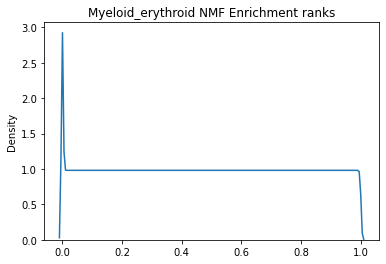

In [15]:
mye_ind = np.where(factor_order == 'Myeloid_erythroid')[0][0]
print(-np.sort(-DHS_NMFenrich_per[:, mye_ind])[:10])
print(len(DHS_NMFenrich_per[:, mye_ind][DHS_NMFenrich_per[:, mye_ind]>0.95]))
fig = kde_wrapper(DHS_NMFenrich_per[:, mye_ind])
plt.title('Myeloid_erythroid NMF Enrichment ranks')

[1.         0.99998842 0.99997685 0.99996527 0.9999537  0.99994212
 0.99993055 0.99991897 0.9999074  0.99989582]
4320
DescribeResult(nobs=88036, minmax=(0.0, 1.0), mean=0.4906742696169748, variance=0.0863578148932465, skewness=0.003365225357098219, kurtosis=-1.2043242837775026)
ModeResult(mode=array([0.]), count=array([1643]))


Text(0.5, 1.0, 'Myeloid_erythroid NMF Sum ranks')

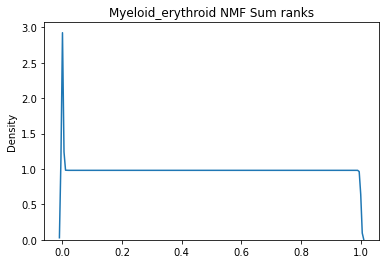

In [16]:
mye_ind = np.where(factor_order == 'Myeloid_erythroid')[0][0]
print(-np.sort(-DHS_NMFsum_per[:, mye_ind])[:10])
print(len(DHS_NMFsum_per[:, mye_ind][DHS_NMFsum_per[:, mye_ind]>0.95]))
fig = kde_wrapper(DHS_NMFsum_per[:, mye_ind])
plt.title('Myeloid_erythroid NMF Sum ranks')

[0.99964117 0.99490699 0.99482018 0.99410832 0.99405044 0.99396363
 0.99350642 0.99332701 0.99317074 0.99292188]
759
DescribeResult(nobs=88036, minmax=(0.0, 0.999641174632204), mean=0.49067426961697497, variance=0.07748841614874175, skewness=-0.17412274586353085, kurtosis=-1.2146861793865713)
ModeResult(mode=array([0.]), count=array([1643]))


Text(0.5, 1.0, 'Myeloid_erythroid NMF Co-ranks')

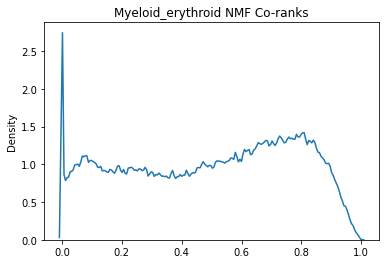

In [17]:
mye_ind = np.where(factor_order == 'Myeloid_erythroid')[0][0]
print(-np.sort(-DHS_per[:, mye_ind])[:10])
print(len(DHS_per[:, mye_ind][DHS_per[:, mye_ind]>0.95]))
fig = kde_wrapper(DHS_per[:, mye_ind])
plt.title('Myeloid_erythroid NMF Co-ranks')

In [29]:
r = regions[np.argsort(-percents[:, mye_ind])[:100]]
v = -np.sort(-percents[:, mye_ind])[:100].reshape(-1, 1)
rv = np.hstack((r, np.round(v, 4)))
roiurl_fusion(rv, 'top_100_myeloid_erythroid')

https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_top_100_myeloid_erythroid_region_chrX_65997358_66022358_25kb_CT20230313.bed
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_top_100_myeloid_erythroid_region_chrX_65997358_66022358_25kb_CT20230313.bed
https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_top_100_myeloid_erythroid_region_chrX_65997358_66022358_25kb_CT20230313.bed


In [34]:
r = regions[np.argsort(-percents[:, mye_ind])[10000:10100]]
v = -np.sort(-percents[:, mye_ind])[10000:10100].reshape(-1, 1)
rv = np.hstack((r, np.round(v, 4)))
roiurl_fusion(rv, 'topmid_100_myeloid_erythroid')

https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_topmid_100_myeloid_erythroid_region_chr15_101104995_101129995_25kb_CT20230313.bed
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_topmid_100_myeloid_erythroid_region_chr15_101104995_101129995_25kb_CT20230313.bed
https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_topmid_100_myeloid_erythroid_region_chr15_101104995_101129995_25kb_CT20230313.bed


In [30]:
r = regions[np.argsort(-percents[:, mye_ind])[44000:44100]]
v = -np.sort(-percents[:, mye_ind])[44000:44100].reshape(-1, 1)
rv = np.hstack((r, np.round(v, 4)))
roiurl_fusion(rv, 'mid_100_myeloid_erythroid')

https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_mid_100_myeloid_erythroid_region_chr7_117156946_117181946_25kb_CT20230313.bed
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_mid_100_myeloid_erythroid_region_chr7_117156946_117181946_25kb_CT20230313.bed
https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_mid_100_myeloid_erythroid_region_chr7_117156946_117181946_25kb_CT20230313.bed


In [31]:
r = regions[np.argsort(-percents[:, mye_ind])[-100:]]
v = -np.sort(-percents[:, mye_ind])[-100:].reshape(-1, 1)
rv = np.hstack((r, np.round(v, 4)))
roiurl_fusion(rv, 'bot_100_myeloid_erythroid')

https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_bot_100_myeloid_erythroid_region_chr2_60183065_60208065_25kb_CT20230313.bed
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_bot_100_myeloid_erythroid_region_chr2_60183065_60208065_25kb_CT20230313.bed
https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_bot_100_myeloid_erythroid_region_chr2_60183065_60208065_25kb_CT20230313.bed


Find regions based on what you want to see

In [9]:
dropdown_options = []
for name, i in zip(factor_order, range(len(factor_order))):
    dropdown_options.append((name, i))

In [10]:
factor_threshod = np.zeros(len(factor_order))

In [11]:
factor_dropdown = widgets.Dropdown(
    options=dropdown_options,
    description='Factor:',
)
factor_dropdown

Dropdown(description='Factor:', options=(('Placental_trophoblast', 0), ('Lymphoid', 1), ('Myeloid_erythroid', …

In [12]:
threshold_slider = widgets.BoundedFloatText(
    value=factor_threshod[factor_dropdown.value] * 100,
    min=0,
    max=100.0,
    step=0.1,
    description='Threshold %',
    disabled=False
)
threshold_slider

BoundedFloatText(value=0.0, description='Threshold %', step=0.1)

In [19]:
#setting threshold values
factor_threshod[factor_dropdown.value] = threshold_slider.value / 100
print(factor_threshod)

[0.   0.   0.   0.   0.98 0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.95 0.   0.   0.   0.   0.  ]


In [23]:
filter_inds = np.where(
    np.count_nonzero(
        percents >= factor_threshod, axis=1
    ) == len(factor_order)
)[0]
print('%s regions available' %(len(filter_inds)))
if len(filter_inds) <= 10:
    for i in filter_inds:
        print(i, print_coords(i))

2 regions available
34493 chr18:76084245-76109245
36303 chr19:56894632-56919632


Select factors

In [7]:
DHS_factors

array(['Placental_trophoblast', 'Lymphoid', 'Myeloid_erythroid',
       'Cardiac', 'Musculoskeletal', 'Vascular_endothelial',
       'Primitive_embryonic', 'Neural', 'Digestive', 'StromalA',
       'StromalB', 'Renal_cancer', 'Cancer_epithelial', 'Pulmonarydevel',
       'Organdevel_renal', 'Tissueinvariant'], dtype='<U21')

In [8]:
epi_factors

array(['TssA', 'TssFlnk', 'TssFlnkU', 'TssFlnkD', 'Tx', 'TxWk', 'EnhG1',
       'EnhG2', 'EnhA1', 'EnhA2', 'EnhWk', 'ZNF_Rpts', 'Het', 'TssBiv',
       'EnhBiv', 'ReprPC', 'ReprPCWk', 'Quies'], dtype='<U8')

In [350]:
target_DHS_ind = np.where(DHS_factors=='Cardiac')[0][0]
target_epi_ind = np.where(epi_factors=='ReprPC')[0][0]
print(target_DHS_ind, target_epi_ind)
target_factors = np.append(target_DHS_ind, target_epi_ind+16)
print(target_factors)

3 15
[ 3 31]


In [351]:
ave_per = ((DHS_per[:, target_DHS_ind]) + 
           (epi_per[:, target_epi_ind])) / 2
for ind in np.argsort(-ave_per)[:20]:
    print(ind,
          print_coords(ind), '\t', 
          np.round(DHS_per[ind, target_DHS_ind], 4), 
          np.round(epi_per[ind, target_epi_ind], 4), 
          np.round(ave_per[ind], 4))

64960 chr5:173227197-173252197 	 0.998 0.9969 0.9975
75620 chr8:11685491-11710491 	 0.9976 0.9951 0.9963
59738 chr5:1865486-1890486 	 0.9929 0.997 0.9949
75621 chr8:11710491-11735491 	 0.9915 0.9959 0.9937
18589 chr12:114434595-114459595 	 0.9905 0.9962 0.9933
64387 chr5:154469840-154494840 	 0.9888 0.9946 0.9917
71508 chr7:35242188-35267389 	 0.9938 0.9874 0.9906
18588 chr12:114392795-114417795 	 0.9859 0.9926 0.9893
75619 chr8:11660491-11685491 	 0.9983 0.9784 0.9884
59156 chr4:173489849-173514849 	 0.9882 0.9856 0.9869
59157 chr4:173514849-173539849 	 0.9957 0.9721 0.9839
26535 chr15:73357259-73382259 	 0.9907 0.9761 0.9834
18479 chr12:111015596-111040596 	 0.9922 0.9719 0.9821
45579 chr20:62511944-62564993 	 0.9882 0.9711 0.9797
76538 chr8:41303081-41328081 	 0.9749 0.9836 0.9793
75993 chr8:23706887-23731887 	 0.9578 0.9947 0.9763
19226 chr13:20137261-20162261 	 0.9706 0.9804 0.9755
47409 chr22:38443995-38469395 	 0.9705 0.9794 0.975
32829 chr18:22158239-22183239 	 0.9898 0.9551 0.

ROI

In [11]:
# roi = 75190 # Primitive_embryonic and EnhBiv
# target_DHS_ind = np.where(DHS_factors=='Primitive_embryonic')[0][0]
# target_epi_ind = np.where(epi_factors=='EnhBiv')[0][0]
# target_factors = np.append(target_DHS_ind, target_epi_ind+16)

# roi = 34493 # Musculoskeletal and Het
# target_DHS_ind = np.where(DHS_factors=='Musculoskeletal')[0][0]
# target_epi_ind = np.where(epi_factors=='Het')[0][0]
# target_factors = np.append(target_DHS_ind, target_epi_ind+16)

# roi = 45463 # Musculoskeletal and ReprPCWk
# target_DHS_ind = np.where(DHS_factors=='Musculoskeletal')[0][0]
# target_epi_ind = np.where(epi_factors=='ReprPCWk')[0][0]
# target_factors = np.append(target_DHS_ind, target_epi_ind+16)

# roi = 22461 # Neural and ReprPC
# target_DHS_ind = np.where(DHS_factors=='Neural')[0][0]
# target_epi_ind = np.where(epi_factors=='ReprPC')[0][0]
# target_factors = np.append(target_DHS_ind, target_epi_ind+16)

roi = 59157 # Cardiac and ReprPC
# target_DHS_ind = np.where(DHS_factors=='Cardiac')[0][0]
# target_epi_ind = np.where(epi_factors=='ReprPC')[0][0]
# target_factors = np.append(target_DHS_ind, target_epi_ind+16)
#using top 2 factors
target_factors = np.argsort(-percents[roi])[:3]
print(factor_order[target_factors])


# target_factors = np.array([target_DHS_ind])

print(target_factors)

['TssBiv' 'EnhBiv' 'Cardiac']
[29 30  3]


Target factors automatically determined by query region

In [10]:
roi = 59157
thresh = 0.9

np.argsort(-percents[roi])[np.where(-np.sort(-percents[roi]) > thresh)[0]]

array([29, 30,  3, 31, 14])

Convolution

In [12]:
roi_percents = percents[roi, target_factors]
print(roi_percents)

[0.99936767 0.99868992 0.99568012]


In [13]:
t = time.time()
roi_conv_all = percents[:, target_factors] * roi_percents
print(time.time()-t)

0.015137195587158203


Fusion

In [14]:
t = time.time()
roi_sim_all = 1 - np.prod(1 - roi_conv_all, axis=1)
print(time.time()-t)

0.007712602615356445


In [15]:
top_regions = np.argsort(-roi_sim_all)[:101]
top_regions = np.append(roi, top_regions[top_regions!=roi][:100])

In [86]:
# find similar regions with an increasing number of factors

# roi = 59157 # Cardiac and ReprPC
# top_regions_by_detail_level = []
# for thresh in range(1, 35):
#     target_factors = np.argsort(-percents[roi])[:thresh]
#     print(factor_order[target_factors], target_factors)
#     print()
#     roi_percents = percents[roi, target_factors]
#     roi_conv_all = percents[:, target_factors] * roi_percents
#     roi_sim_all = 1 - np.prod(1 - roi_conv_all, axis=1)
#     top_regions = np.argsort(-roi_sim_all)[:101]
#     top_regions = np.append(roi, top_regions[top_regions!=roi][:100])
#     top_regions_by_detail_level.append(top_regions)
# top_regions_by_detail_level = np.array(top_regions_by_detail_level)

['TssBiv'] [29]

['TssBiv' 'EnhBiv'] [29 30]

['TssBiv' 'EnhBiv' 'Cardiac'] [29 30  3]

['TssBiv' 'EnhBiv' 'Cardiac' 'ReprPC'] [29 30  3 31]

['TssBiv' 'EnhBiv' 'Cardiac' 'ReprPC' 'Organdevel_renal'] [29 30  3 31 14]

['TssBiv' 'EnhBiv' 'Cardiac' 'ReprPC' 'Organdevel_renal'
 'Primitive_embryonic'] [29 30  3 31 14  6]

['TssBiv' 'EnhBiv' 'Cardiac' 'ReprPC' 'Organdevel_renal'
 'Primitive_embryonic' 'Neural'] [29 30  3 31 14  6  7]

['TssBiv' 'EnhBiv' 'Cardiac' 'ReprPC' 'Organdevel_renal'
 'Primitive_embryonic' 'Neural' 'StromalB'] [29 30  3 31 14  6  7 10]

['TssBiv' 'EnhBiv' 'Cardiac' 'ReprPC' 'Organdevel_renal'
 'Primitive_embryonic' 'Neural' 'StromalB' 'Musculoskeletal'] [29 30  3 31 14  6  7 10  4]

['TssBiv' 'EnhBiv' 'Cardiac' 'ReprPC' 'Organdevel_renal'
 'Primitive_embryonic' 'Neural' 'StromalB' 'Musculoskeletal' 'Digestive'] [29 30  3 31 14  6  7 10  4  8]

['TssBiv' 'EnhBiv' 'Cardiac' 'ReprPC' 'Organdevel_renal'
 'Primitive_embryonic' 'Neural' 'StromalB' 'Musculoskeletal' 'Digest

['TssBiv' 'EnhBiv' 'Cardiac' 'ReprPC' 'Organdevel_renal'
 'Primitive_embryonic' 'Neural' 'StromalB' 'Musculoskeletal' 'Digestive'
 'TssFlnkD' 'EnhG2' 'TssFlnk' 'Pulmonarydevel' 'StromalA'
 'Myeloid_erythroid' 'TssA' 'EnhA2' 'TssFlnkU' 'Tissueinvariant'
 'Placental_trophoblast' 'Lymphoid' 'Vascular_endothelial' 'Renal_cancer'
 'Cancer_epithelial' 'TxWk' 'EnhG1' 'ReprPCWk' 'EnhA1' 'EnhWk' 'ZNF_Rpts'
 'Het' 'Tx'] [29 30  3 31 14  6  7 10  4  8 19 23 17 13  9  2 16 25 18 15  0  1  5 11
 12 21 22 32 24 26 27 28 20]

['TssBiv' 'EnhBiv' 'Cardiac' 'ReprPC' 'Organdevel_renal'
 'Primitive_embryonic' 'Neural' 'StromalB' 'Musculoskeletal' 'Digestive'
 'TssFlnkD' 'EnhG2' 'TssFlnk' 'Pulmonarydevel' 'StromalA'
 'Myeloid_erythroid' 'TssA' 'EnhA2' 'TssFlnkU' 'Tissueinvariant'
 'Placental_trophoblast' 'Lymphoid' 'Vascular_endothelial' 'Renal_cancer'
 'Cancer_epithelial' 'TxWk' 'EnhG1' 'ReprPCWk' 'EnhA1' 'EnhWk' 'ZNF_Rpts'
 'Het' 'Tx' 'Quies'] [29 30  3 31 14  6  7 10  4  8 19 23 17 13  9  2 16 25 18 15 

In [87]:
# out_f = datadir + 'selective_search.detail_level_factor_selection.top100_regions.roi_' + str(roi) + '_CT20230228.tsv'
# print(out_f)
# np.savetxt(out_f, top_regions_by_detail_level, delimiter='\t', fmt='%s')

/home/ctrader/region_similarity/data/rank_based/selective_search.detail_level_factor_selection.top100_regions.roi_59157_CT20230228.tsv


In [88]:
# roi_factor_ind_order = np.argsort(-percents[roi])
# roi_factor_order = factor_order[roi_factor_ind_order]
# out_factor = np.vstack((roi_factor_order, roi_factor_ind_order))

# out_f = datadir + 'selective_search.detail_level_factor_selection.factor_order.roi_' + str(roi) + '_CT20230228.tsv'
# print(out_f)
# np.savetxt(out_f, out_factor, delimiter='\t', fmt='%s')

/home/ctrader/region_similarity/data/rank_based/selective_search.detail_level_factor_selection.factor_order.roi_59157_CT20230228.tsv


CLT to determine significance of percentiles we see

In [34]:
factor_order

array(['Placental_trophoblast', 'Lymphoid', 'Myeloid_erythroid',
       'Cardiac', 'Musculoskeletal', 'Vascular_endothelial',
       'Primitive_embryonic', 'Neural', 'Digestive', 'StromalA',
       'StromalB', 'Renal_cancer', 'Cancer_epithelial', 'Pulmonarydevel',
       'Organdevel_renal', 'Tissueinvariant', 'TssA', 'TssFlnk',
       'TssFlnkU', 'TssFlnkD', 'Tx', 'TxWk', 'EnhG1', 'EnhG2', 'EnhA1',
       'EnhA2', 'EnhWk', 'ZNF_Rpts', 'Het', 'TssBiv', 'EnhBiv', 'ReprPC',
       'ReprPCWk', 'Quies'], dtype='<U21')

In [49]:
all_mean = np.mean(percents, axis=0)
all_std = np.std(percents, axis=0)

top_region_mean = np.mean(percents[top_regions[1:]], axis=0)

Z = (top_region_mean - all_mean) / (all_std / np.sqrt(len(top_regions[1:])))

pval = stats.norm.sf(Z)
pval

array([5.30954685e-004, 1.03687111e-021, 3.36350614e-013, 3.14455119e-024,
       1.99712585e-019, 1.77763778e-011, 1.22941114e-061, 1.09103275e-046,
       1.46405467e-014, 1.52681478e-001, 2.42708935e-008, 1.70664861e-005,
       4.35877712e-001, 4.58488935e-011, 1.30595414e-057, 1.16478761e-004,
       7.92464454e-051, 4.10797641e-064, 1.38065574e-027, 1.32033418e-044,
       9.97885487e-001, 9.99994695e-001, 8.08878698e-005, 1.35742158e-031,
       9.79095683e-001, 5.51182974e-001, 9.98206836e-001, 9.99999999e-001,
       1.00000000e+000, 0.00000000e+000, 9.54204760e-199, 9.93474044e-245,
       1.31946924e-020, 1.00000000e+000])

In [51]:
Z[np.where(Z < 0)[0]], pval[np.where(Z < 0)[0]]

(array([-2.8605532 , -4.40437101, -2.03541996, -0.12865069, -2.91242626,
        -6.06874773, -6.62572568, -9.84258949]),
 array([0.99788549, 0.9999947 , 0.97909568, 0.55118297, 0.99820684,
        1.        , 1.        , 1.        ]))

In [65]:
metriccolors = {
    'DHSs': '<span style="color:#0000CD">',
    'chromatin states': '<span style="color:#FF0000">',
    'STANDARD': '</span>',
    'BOLD': '<b>',
    'UNBOLD': '</b>'
}

factor_order = np.append(DHS_factors, epi_factors)
metric_order = np.append(np.array(['DHSs'] * len(DHS_factors)),
                         np.array(['chromatin states'] * len(epi_factors)))

factor_order = factor_order.astype(object)
for i in range(len(factor_order)):
    factor_order[i] = metriccolors[metric_order[i]] + factor_order[i] + metriccolors['STANDARD']
factor_order

array(['<span style="color:#0000CD">Placental_trophoblast</span>',
       '<span style="color:#0000CD">Lymphoid</span>',
       '<span style="color:#0000CD">Myeloid_erythroid</span>',
       '<span style="color:#0000CD">Cardiac</span>',
       '<span style="color:#0000CD">Musculoskeletal</span>',
       '<span style="color:#0000CD">Vascular_endothelial</span>',
       '<span style="color:#0000CD">Primitive_embryonic</span>',
       '<span style="color:#0000CD">Neural</span>',
       '<span style="color:#0000CD">Digestive</span>',
       '<span style="color:#0000CD">StromalA</span>',
       '<span style="color:#0000CD">StromalB</span>',
       '<span style="color:#0000CD">Renal_cancer</span>',
       '<span style="color:#0000CD">Cancer_epithelial</span>',
       '<span style="color:#0000CD">Pulmonarydevel</span>',
       '<span style="color:#0000CD">Organdevel_renal</span>',
       '<span style="color:#0000CD">Tissueinvariant</span>',
       '<span style="color:#FF0000">TssA</span>',
  

Score distribution

DescribeResult(nobs=88036, minmax=(0.0, 0.9998064760007697), mean=0.5306811189427004, variance=0.0891781535998772, skewness=-0.24310335687399137, kurtosis=-1.2248368740387368)
ModeResult(mode=array([0.]), count=array([2056]))


Text(0.5, 1.0, 'Score Distribution for ROI 59157')

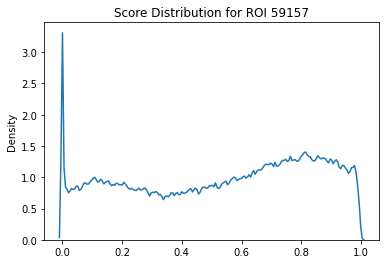

In [429]:
fig = kde_wrapper(roi_sim_all)
plt.title('Score Distribution for ROI ' + str(roi))

In [430]:
print(len(roi_sim_all[roi_sim_all>0]))
print(len(roi_sim_all[roi_sim_all>0.9]))
print(len(roi_sim_all[roi_sim_all>0.99]))
print(len(roi_sim_all[roi_sim_all>0.999]))
print(len(roi_sim_all[roi_sim_all>0.9999]))
print(len(roi_sim_all[roi_sim_all>0.99999]))
print(len(roi_sim_all[roi_sim_all>0.999999]))
print(len(roi_sim_all[roi_sim_all==1]))

85980
9620
440
14
0
0
0
0


In [431]:
# inds_over_thresh = np.where(percents[top_regions[0]] > 0.9)[0]
# print('Query:',
#       top_regions[0],
#       len(inds_over_thresh),
#       factor_order[inds_over_thresh],
#       percents[top_regions[0]][inds_over_thresh],
#       print_coords(top_regions[0])
#      )
# print()

# for region in top_regions[1:11]:
#     inds_over_thresh = np.where(roi_conv_all[region] > 0.9)[0]
#     print(region,
#           np.round(roi_sim_all[region], 9),
#           len(inds_over_thresh),
#           factor_order[target_factors][inds_over_thresh],
#           percents[region, target_factors][inds_over_thresh],
#           np.round(np.max(roi_conv_all[region]), 4),
#           print_coords(region)
#          )
#     print()

In [432]:
inds_over_thresh = np.where(percents[top_regions[0]] > 0.9)[0]
print('Query:',
      top_regions[0],
      len(inds_over_thresh),
      factor_order[inds_over_thresh],
      percents[top_regions[0]][inds_over_thresh],
      print_coords(top_regions[0])
     )
print()

for region in top_regions[1:11]:
    inds_over_thresh = np.where(percents[region] > 0.9)[0]
    print(region,
          np.round(roi_sim_all[region], 9),
          len(inds_over_thresh),
          factor_order[inds_over_thresh],
#           percents[region][inds_over_thresh],
#           np.round(np.max(roi_conv_all[region]), 4),
          print_coords(region)
         )
    print()

Query: 59157 7 ['Cardiac' 'Primitive_embryonic' 'Neural' 'Organdevel_renal' 'TssBiv'
 'EnhBiv' 'ReprPC'] [0.99568012 0.93560404 0.91396854 0.95335056 0.99936767 0.99868992
 0.97206869] chr4:173514849-173539849

64960 0.999806476 6 ['Cardiac' 'Primitive_embryonic' 'Organdevel_renal' 'TssBiv' 'EnhBiv'
 'ReprPC'] chr5:173227197-173252197

75620 0.999780833 6 ['Cardiac' 'Primitive_embryonic' 'Digestive' 'TssBiv' 'EnhBiv' 'ReprPC'] chr8:11685491-11710491

75619 0.999706021 6 ['Cardiac' 'Primitive_embryonic' 'Digestive' 'TssBiv' 'EnhBiv' 'ReprPC'] chr8:11660491-11685491

59738 0.99964759 6 ['Cardiac' 'Primitive_embryonic' 'Cancer_epithelial' 'TssBiv' 'EnhBiv'
 'ReprPC'] chr5:1865486-1890486

75621 0.999590698 3 ['Cardiac' 'EnhBiv' 'ReprPC'] chr8:11710491-11735491

71508 0.999578273 7 ['Cardiac' 'Primitive_embryonic' 'Neural' 'Organdevel_renal' 'TssBiv'
 'EnhBiv' 'ReprPC'] chr7:35242188-35267389

18589 0.999564824 5 ['Cardiac' 'Primitive_embryonic' 'Pulmonarydevel' 'EnhBiv' 'ReprPC'] chr12:11

0
0
0
106
5159
82771


Text(0.5, 1.0, 'Number of factors filtering')

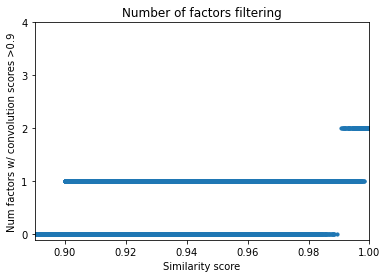

In [433]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(roi_sim_all, np.count_nonzero(roi_conv_all > 0.9, axis=1), s=10)

plt.xlim([0.89, 1])
plt.yticks([0, 1, 2, 3, 4])

plt.xlabel('Similarity score')
plt.ylabel('Num factors w/ convolution scores >0.9')
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==5))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==4))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==3))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==2))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==1))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==0))
plt.title('Number of factors filtering')

In [434]:
# top_inds = top_regions[:100]

# top_r = regions[top_inds]
# top_factors_per_r = []
# for ind in top_inds:
#     factors_over_thresh = np.where(roi_conv_all[ind] > 0.9)[0]
#     top_factors_per_r.append('/'.join(factor_order[target_factors][factors_over_thresh]))
# top_factors_per_r = np.array(top_factors_per_r)
# top_r = np.hstack((top_r, top_factors_per_r.reshape(-1, 1)))

In [435]:
top_inds = top_regions[:100]

top_r = regions[top_inds]
top_factors_per_r = []
factors_over_thresh_arr = np.array([], dtype=int)
regions_with_all_targets = np.array([], dtype=int)
for ind in top_inds:
    factors_over_thresh = np.where(percents[ind] > 0.9)[0]
    factors_over_thresh_arr = np.append(factors_over_thresh_arr, factors_over_thresh)
    if (len(factors_over_thresh[np.isin(factors_over_thresh, target_factors)]) == 
        len(target_factors)):
        regions_with_all_targets = np.append(regions_with_all_targets, ind)
    top_factors_per_r.append('/'.join(factor_order[factors_over_thresh]))
top_factors_per_r = np.array(top_factors_per_r)
top_r = np.hstack((top_r, top_factors_per_r.reshape(-1, 1)))

on_target_per = (len(factors_over_thresh_arr[np.isin(factors_over_thresh_arr, target_factors)]) / 
                 len(factors_over_thresh_arr))
print('roi = %s' %roi)
print('On target factors = %s' %factor_order[target_factors])
print('On target fraction = %s' %np.round(on_target_per, 4))
print('Fraction of regions with all target factors = %s' %(len(regions_with_all_targets) / len(top_inds)))

roi = 59157
On target factors = ['Cardiac' 'ReprPC']
On target fraction = 0.3282
Fraction of regions with all target factors = 0.7


In [18]:
def roiurl_fusion(top_regions, method):
    today = date.today()
    query_region = '_'.join(top_regions[0, :3])
    roiurl_name = 'selective_search_convolution_fusion_similarities_' + method + '_region_' + query_region + '_25kb_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roiurl_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path_epi = 'https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    link_path_index = 'https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    link_path_both = 'https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    print(link_path_epi)
    print(link_path_index)
    print(link_path_both)
    return # link_path_epi, link_path_index

In [437]:
roiurl_fusion(top_r)

https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_region_chr4_173514849_173539849_25kb_CT20230214.bed
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_region_chr4_173514849_173539849_25kb_CT20230214.bed
https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fselective_search_convolution_fusion_similarities_region_chr4_173514849_173539849_25kb_CT20230214.bed


Text(0.5, 1.0, 'Max convolution score filtering')

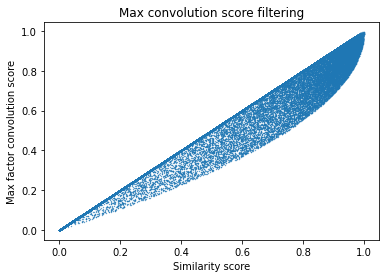

In [438]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(roi_sim_all, np.max(roi_conv_all, axis=1), s=0.1)

# plt.xlim([0.9, 1])
# plt.ylim([0.5, 1])
plt.xlabel('Similarity score')
plt.ylabel('Max factor convolution score')
plt.title('Max convolution score filtering')

**Narrate**

In [459]:
metriccolors = {
    'DHSs': '\033[94m',
    'TF': '\033[92m',
    'chromatin states': '\033[91m',
    'STANDARD': '\033[0m',
    'BOLD': '\033[1m',
    'UNDERLINE': '\033[4m'
}

epi_conversion_dict = {
    'EnhA1': 'active enhancer 1',
    'EnhA2': 'active enhancer 2',
    'EnhBiv': 'bivalent enhancer',
    'EnhG1': 'genic enhancer 1',
    'EnhG2': 'genic enhancer 2',
    'EnhWk': 'weak enhancer',
    'Het': 'heterochromatin',
    'Quies': 'quiescent',
    'ReprPC': 'repressed polycomb',
    'ReprPCWk': 'weak repressed polycomb',
    'TssA': 'active TSS',
    'TssBiv': 'bivalent TSS',
    'TssFlnk': 'flanking TSS',
    'TssFlnkD': 'downstream flanking TSS',
    'TssFlnkU': 'upstream flanking TSS',
    'Tx': 'strong transcription',
    'TxWk': 'weak transcription',
    'ZNF_Rpts': 'ZNF genes + repeats'
}

DHS_conversion_dict = {
    'Cancer_epithelial': 'cancer/epithelial',
    'Cardiac': 'cardiac',
    'Digestive': 'digestive',
    'Lymphoid': 'lymphoid',
    'Musculoskeletal': 'musculoskeletal',
    'Myeloid_erythroid': 'myeloid/erythroid',
    'Neural': 'neural',
    'Organdevel_renal': 'organ development/renal',
    'Placental_trophoblast': 'placental/trophoblast',
    'Primitive_embryonic': 'primitive/embryonic',
    'Pulmonarydevel': 'pulmonary development',
    'Renal_cancer': 'renal/cancer',
    'StromalA': 'stromal A',
    'StromalB': 'stromal B',
    'Tissueinvariant': 'tissue invariant',
    'Vascular_endothelial': 'vascular/endothelial'
}

def narrate_sim(top_regions, roi_conv_top, factor_order, metric_order, thresh=0.9):
    query = top_regions[0]
    hits = top_regions[1:]
    roi_conv_hits = roi_conv_top[1:]
    sentences = []
    for region, roi_conv_hit in zip(hits, roi_conv_hits):
        sim_factors = np.where(roi_conv_hit > thresh)[0]
        if len(sim_factors) > 0:
            sentence = 'This region is highly similar to the query region in terms of '
            sim_factor_names = factor_order[sim_factors]
            sim_metric_names = metric_order[sim_factors]
            m_sections = []
            for m in np.unique(sim_metric_names):
                m_inds = np.where(sim_metric_names == m)[0]
                m_factors = sim_factor_names[m_inds]
                factors_joined = metriccolors[m]
                if len(m_factors) > 2:
                    factors_joined += ', '.join(m_factors[:-1])
                    factors_joined += ', and ' + m_factors[-1]
                elif len(m_factors) == 2:
                    factors_joined += ' and '.join(m_factors)
                else:
                    factors_joined += m_factors[0]
                    
                factors_joined += ' ' + m + metriccolors['STANDARD']
                m_sections.append(factors_joined)
            if len(m_sections) > 2:
                metrics_joined = ', '.join(m_sections[:-1])
                metrics_joined += ', and ' + m_sections[-1]
            if len(m_sections) == 2:
                metrics_joined = ' and '.join(m_sections)
            else:
                metrics_joined = m_sections[0]
                
            sentence += metrics_joined + '.'
        
        else:
            sentence = ''
        sentences.append(sentence)
    return sentences

sentences = narrate_sim(top_regions, 
                        roi_conv_all[top_regions], 
                        factor_order[target_factors], 
                        metric_order[target_factors])

for s in sentences:
    print(s)

This region is highly similar to the query region in terms of Cardiac DHSs and ReprPC chromatin states.
This region is highly similar to the query region in terms of Cardiac DHSs and ReprPC chromatin states.
This region is highly similar to the query region in terms of Cardiac DHSs and ReprPC chromatin states.
This region is highly similar to the query region in terms of Cardiac DHSs and ReprPC chromatin states.
This region is highly similar to the query region in terms of Cardiac DHSs and ReprPC chromatin states.
This region is highly similar to the query region in terms of Cardiac DHSs and ReprPC chromatin states.
This region is highly similar to the query region in terms of Cardiac DHSs and ReprPC chromatin states.
This region is highly similar to the query region in terms of Cardiac DHSs and ReprPC chromatin states.
This region is highly similar to the query region in terms of Cardiac DHSs and ReprPC chromatin states.
This region is highly similar to the query region in terms of Ca

**Tree plots**

In [461]:
percents[roi]

array([0.43273653, 0.3782752 , 0.55604621, 0.99568012, 0.74621954,
       0.356916  , 0.93560404, 0.91396854, 0.70213792, 0.5674926 ,
       0.78847281, 0.18804763, 0.15146076, 0.60809231, 0.95335056,
       0.44105236, 0.55470914, 0.63871579, 0.49551651, 0.6586735 ,
       0.        , 0.        , 0.        , 0.64462744, 0.        ,
       0.52693599, 0.        , 0.        , 0.        , 0.99936767,
       0.99868992, 0.97206869, 0.        , 0.        ])

Text(0.5, 0.91, 'Query Region Percentiles')

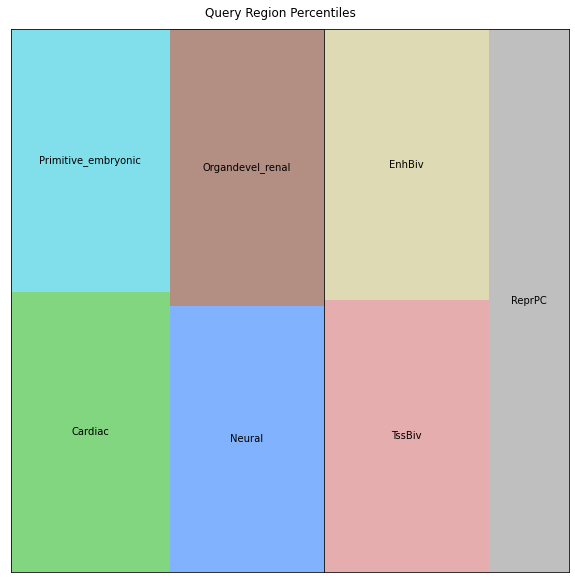

In [460]:
#query
factor_sums = percents[roi]
nonzero_inds = np.where(factor_sums>0.8)[0]
nonzero_factors = factor_sums[nonzero_inds]
nonzero_names = factor_order[nonzero_inds]
nonzero_color = colors[nonzero_inds]
nonzero_metrics = metric_order[nonzero_inds]

plot_ratios = []
for metric in np.unique(nonzero_metrics):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    plot_ratios.append(np.sum(nonzero_factors[metric_inds]))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,10), gridspec_kw={'width_ratios': plot_ratios})
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0)

axes = axes.ravel()

for ax, metric in zip(axes, np.unique(nonzero_metrics)):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    squarify.plot(sizes=nonzero_factors[metric_inds], 
                  label=nonzero_names[metric_inds], 
                  alpha=0.5, 
                  color=nonzero_color[metric_inds],
                  ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
    
fig.suptitle('Query Region Percentiles', y=0.91)

Text(0.5, 0.91, 'Similar Region 1 Percentiles')

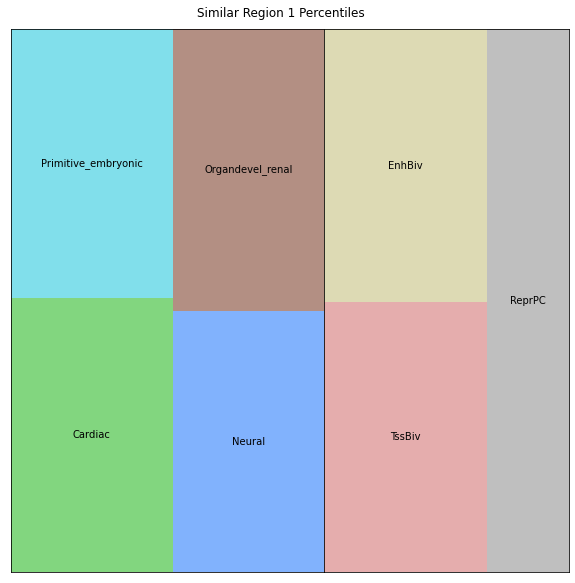

In [462]:
#hits

hit = 1
factor_sums = percents[top_regions[hit]]
nonzero_inds = np.where(factor_sums>0.85)[0]
nonzero_factors = factor_sums[nonzero_inds]
nonzero_names = factor_order[nonzero_inds]
nonzero_color = colors[nonzero_inds]
nonzero_metrics = metric_order[nonzero_inds]

plot_ratios = []
for metric in np.unique(nonzero_metrics):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    plot_ratios.append(np.sum(nonzero_factors[metric_inds]))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,10), gridspec_kw={'width_ratios': plot_ratios})
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0)

axes = axes.ravel()

for ax, metric in zip(axes, np.unique(nonzero_metrics)):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    squarify.plot(sizes=nonzero_factors[metric_inds], 
                  label=nonzero_names[metric_inds], 
                  alpha=0.5, 
                  color=nonzero_color[metric_inds],
                  ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
    
fig.suptitle('Similar Region %s Percentiles' %(hit), y=0.91)

Text(0.5, 0.91, 'Similar Regions 1-10 Convolution Scores')

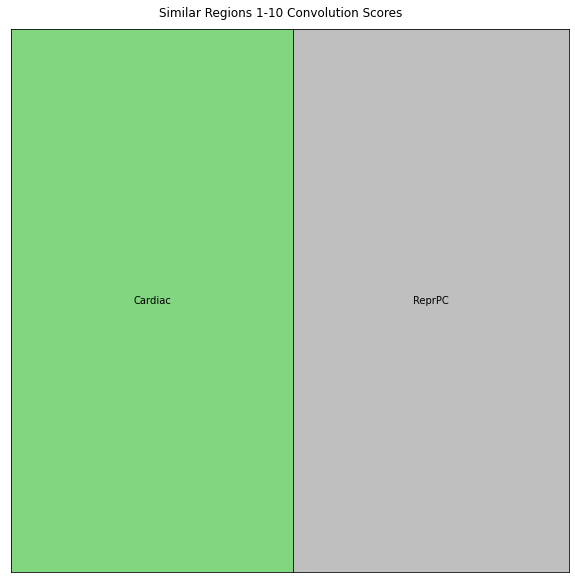

In [474]:
#top hits
start_hit = 1
end_hit = 10
factor_sums = np.sum(roi_conv_all[top_regions[start_hit:end_hit+1]], axis=0)
nonzero_inds = np.where(factor_sums>0.9)[0]
nonzero_factors = factor_sums[nonzero_inds]
nonzero_names = factor_order[target_factors][nonzero_inds]
nonzero_color = colors[target_factors][nonzero_inds]
nonzero_metrics = metric_order[target_factors][nonzero_inds]


plot_ratios = []
for metric in np.unique(nonzero_metrics):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    plot_ratios.append(np.sum(nonzero_factors[metric_inds]))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,10), gridspec_kw={'width_ratios': plot_ratios})
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0)

axes = axes.ravel()

for ax, metric in zip(axes, np.unique(nonzero_metrics)):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    squarify.plot(sizes=nonzero_factors[metric_inds], 
                  label=nonzero_names[metric_inds], 
                  alpha=0.5, 
                  color=nonzero_color[metric_inds],
                  ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle('Similar Regions %s-%s Convolution Scores' %(start_hit, end_hit), y=0.91)